# 15-puzzle glissant — heuristiques admissibles mesurées (Manhattan, linear conflict)

**Référence canonique de l'algorithme A\*** : le 15-puzzle glissant est l'exemple par lequel tout cours introduit la recherche informée. Il réunit les trois ingrédients qui font la valeur pédagogique du problème :

1. un **espace d'états** parfaitement défini — 16 tuiles sur une grille 4×4, une case vide, quatre déplacements possibles ;
2. un **invariant non trivial** — la parité du nombre d'inversions (combinée à la ligne de la case vide) sépare les configurations résolubles des configurations impossibles ;
3. des **heuristiques admissibles** dont la force se **mesure** — Manhattan, puis *linear conflict*, qui domine Manhattan sans jamais surestimer le coût restant.

Le carnet ne se contente pas d'affirmer que « linear conflict est meilleure » : il fait tourner les trois recherches sur un jeu de puzzles à graine fixe et reporte les **nœuds développés** et le **coût de la solution**. Ce que la mesure établit : à coût **identique** (les deux heuristiques sont admissibles, donc A\* reste optimal), linear conflict développe en médiane **2,2 fois** moins de nœuds, jusqu'à **3,7 fois** moins ; sur les deux puzzles les plus profonds, Manhattan épuise son budget sans trouver de solution là où linear conflict aboutit, et les deux finissent par céder sur le plus dur. La recherche gloutonne, elle, aboutit vite mais rend des solutions **deux à quatre fois et demie plus longues** que l'optimum.

Ce carnet complète la série d'applications `Applications/` de la série Search, après les problèmes CSP (N-Reines, coloration, Picross, Sudoku) et les problèmes d'optimisation combinatoire (TSP, VRP).

## 1. L'espace d'états $(S, s_0, A, T, G)$

L'état est un uplet de 16 entiers : la grille lue en ordre de lecture, `0` désignant la case vide. Le but est `(1, 2, …, 15, 0)`.

| Composant | Définition dans ce carnet |
|---|---|
| $S$ | les $16! / 2 = 10\,461\,394\,944\,000$ configurations atteignables depuis le but |
| $s_0$ | une configuration produite par une marche aléatoire sans demi-tour depuis le but (donc **résoluble par construction**), de difficulté révélée par le coût de sa solution |
| $A$ | déplacer une tuile adjacente dans la case vide — au plus 4 actions, 2 dans un coin |
| $T$ | permutation des deux positions concernées |
| $G$ | la grille identité |

Une remarque de modélisation : le coût d'une action vaut **1**, ce qui rend le coût d'une solution égal au **nombre de coups**. C'est cette uniformité qui permet de comparer directement les heuristiques entre elles.

In [1]:
from collections import deque
from heapq import heappush, heappop
import itertools, math, time
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
N, SIDE = 16, 4
GOAL = tuple(range(1, N)) + (0,)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def show(state):
    """Rend une configuration lisible : 4 lignes, case vide en point."""
    rows = []
    for r in range(SIDE):
        rows.append(" ".join("." if v == 0 else f"{v:2d}" for v in state[r * SIDE:(r + 1) * SIDE]))
    return "\n".join(rows)


def neighbors(state):
    """Successeurs legaux : la case vide echange avec une tuile adjacente."""
    i = state.index(0)
    r, c = divmod(i, SIDE)
    out = []
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        nr, nc = r + dr, c + dc
        if 0 <= nr < SIDE and 0 <= nc < SIDE:
            j = nr * SIDE + nc
            child = list(state)
            child[i], child[j] = child[j], child[i]
            out.append(tuple(child))
    return out


print("But :")
print(show(GOAL))
print(f"\nNombre d'etats atteignables : 16!/2 = {math.factorial(16)//2:,}")

But :
 1  2  3  4
 5  6  7  8
 9 10 11 12
13 14 15 .

Nombre d'etats atteignables : 16!/2 = 10,461,394,944,000


## 2. Résolvabilité — l'invariant de parité, mesuré

Toutes les permutations de 16 tuiles ne sont pas atteignables. Pour une grille 4×4, une configuration est **résoluble** si et seulement si :

$$\big(\text{nombre d'inversions}\big) + \big(\text{ligne de la case vide, comptée depuis le bas}\big) \equiv 0 \pmod 2$$

où une *inversion* est une paire de tuiles numérotées dont l'ordre est inversé par rapport au but (la case vide n'entre pas dans le compte).

Deux mesures valent mieux qu'une affirmation :

- **contrôle positif** — une marche aléatoire depuis le but ne doit **jamais** produire une configuration insoluble (l'invariant est préservé par toute action légale) ;
- **contrôle négatif** — sur des permutations uniformes, la proportion de résolubles doit tomber près de $1/2$ ; si elle tombait à 1, le test ne testerait rien.

In [2]:
def inversions(state):
    """Paires de tuiles numerotees dont l'ordre est inverse par rapport au but."""
    tiles = [v for v in state if v != 0]
    return sum(1 for a, b in itertools.combinations(tiles, 2) if a > b)


def blank_row_from_bottom(state):
    return SIDE - state.index(0) // SIDE


def is_solvable(state):
    """Critere de parite pour une grille 4x4 (largeur paire).

    Convention : inversions + ligne de la case vide comptee depuis le bas (1-based)
    doit etre IMPAIRE. Verifie plus bas par deux controles, dont le but lui-meme.
    """
    return (inversions(state) + blank_row_from_bottom(state)) % 2 == 1


rng = np.random.default_rng(SEED)

# Controle positif : 300 marches aleatoires de 200 coups depuis le but.
walks_solvable = 0
WALKS, LENGTH = 300, 200
for _ in range(WALKS):
    s = GOAL
    for _ in range(LENGTH):
        nxt = neighbors(s)
        s = nxt[rng.integers(len(nxt))]
    walks_solvable += is_solvable(s)

# Controle negatif : 2000 permutations uniformes, sans marche.
shuffles = [tuple(int(v) for v in rng.permutation(N)) for _ in range(2000)]
uniform_solvable = sum(is_solvable(s) for s in shuffles)

# Controle de base : le but est resoluble, la grille 14-15 classique ne l'est pas.
PUZZLE_14_15 = tuple(list(range(1, 14)) + [15, 14, 0])

print(f"Marches aleatoires        : {walks_solvable}/{WALKS} resolubles")
print(f"Permutations uniformes    : {uniform_solvable}/2000 resolubles "
      f"({uniform_solvable/2000:.1%})")
print(f"But (doit etre resoluble)          : {is_solvable(GOAL)}")
print(f"Grille 14-15 (doit etre insoluble) : {is_solvable(PUZZLE_14_15)}")

Marches aleatoires        : 300/300 resolubles


Permutations uniformes    : 1005/2000 resolubles (50.2%)
But (doit etre resoluble)          : True
Grille 14-15 (doit etre insoluble) : False


Les deux contrôles se comportent comme l'invariant l'exige : **toutes** les marches aléatoires restent résolubles (l'invariant est conservé par construction), et les permutations uniformes se partagent en deux classes à peu près égales. La moitié insoluble de l'espace est donc bien **hors d'atteinte** de toute recherche : un solveur qui l'ignorerait chercherait indéfiniment.

C'est le premier piège pédagogique du 15-puzzle : un état tiré au hasard a une chance sur deux de n'avoir **aucune** solution, quelle que soit la qualité de l'algorithme.

## 3. Les heuristiques — Manhattan et linear conflict

**Manhattan** : pour chaque tuile, la distance de sa position courante à sa position but, en déplacements horizontaux et verticaux. Chaque coup déplace une seule tuile d'une case : la somme est donc un **minorant** du nombre de coups restants.

**Linear conflict** : Manhattan, plus un supplément de **2** par paire de tuiles qui sont toutes deux dans leur ligne (ou colonne) but mais dans l'ordre inverse — il faut alors au moins deux coups de plus pour les remettre dans l'ordre. L'heuristique reste **admissible**, et elle **domine** Manhattan : `lc ≥ manhattan` partout.

La domination est une propriété, pas une opinion : la cellule suivante la mesure sur un échantillon, et vérifie surtout l'**admissibilité** — aucune heuristique ne doit dépasser la distance optimale réelle.

In [3]:
GOAL_POS = {v: divmod(i, SIDE) for i, v in enumerate(GOAL)}


def manhattan(state):
    total = 0
    for i, v in enumerate(state):
        if v == 0:
            continue
        r, c = divmod(i, SIDE)
        gr, gc = GOAL_POS[v]
        total += abs(r - gr) + abs(c - gc)
    return total


def linear_conflict(state):
    """Manhattan + 2 par paire de tuiles en conflit lineaire (ligne ou colonne)."""
    h = manhattan(state)
    for line in range(SIDE):
        # Ligne `line` : tuiles presentes dans leur ligne but, ordonnees a l'envers.
        in_row = [(c, state[line * SIDE + c]) for c in range(SIDE)
                  if state[line * SIDE + c] != 0 and GOAL_POS[state[line * SIDE + c]][0] == line]
        for (c1, t1), (c2, t2) in itertools.combinations(in_row, 2):
            if (c1 - c2) * (GOAL_POS[t1][1] - GOAL_POS[t2][1]) < 0:
                h += 2
        # Colonne `line` : meme raisonnement verticalement.
        in_col = [(r, state[r * SIDE + line]) for r in range(SIDE)
                  if state[r * SIDE + line] != 0 and GOAL_POS[state[r * SIDE + line]][1] == line]
        for (r1, t1), (r2, t2) in itertools.combinations(in_col, 2):
            if (r1 - r2) * (GOAL_POS[t1][0] - GOAL_POS[t2][0]) < 0:
                h += 2
    return h


def bfs_distances(max_depth):
    """Distances exactes au but par parcours en largeur : la verite terrain."""
    dist = {GOAL: 0}
    frontier = deque([GOAL])
    while frontier:
        s = frontier.popleft()
        d = dist[s]
        if d == max_depth:
            continue
        for t in neighbors(s):
            if t not in dist:
                dist[t] = d + 1
                frontier.append(t)
    return dist


t0 = time.perf_counter()
TRUTH = bfs_distances(14)
bfs_seconds = time.perf_counter() - t0

# Echantillon de verite terrain : etats a distance exacte connue, assez eloignes du but.
sample = [s for s, d in TRUTH.items() if 8 <= d <= 14][:500]
rows = [(TRUTH[s], manhattan(s), linear_conflict(s)) for s in sample]
h_star = np.array([r[0] for r in rows])
h_man = np.array([r[1] for r in rows])
h_lc = np.array([r[2] for r in rows])

print(f"Verite terrain : {len(TRUTH):,} etats a distance <= 14 du but ({bfs_seconds:.2f} s)")
print(f"Echantillon evalue : {len(sample)} etats (distance optimale 8 a 14)")
print(f"Admissibilite  Manhattan       : max(h* - h) = {(h_star - h_man).min():+d}, "
      f"violations = {(h_man > h_star).sum()}")
print(f"Admissibilite  Linear conflict : max(h* - h) = {(h_star - h_lc).min():+d}, "
      f"violations = {(h_lc > h_star).sum()}")

# Sur ces etats proches du but, les conflits lineaires sont rares : on mesure la
# domination sur des etats tires plus loin, ou les tuiles se disputent les lignes.
rng_dom = np.random.default_rng(SEED + 1)
far = []
for _ in range(500):
    s, prev = GOAL, None
    for _ in range(int(rng_dom.integers(20, 40))):
        nxt = [t for t in neighbors(s) if t != prev] or neighbors(s)
        prev, s = s, nxt[rng_dom.integers(len(nxt))]
    far.append(s)
far_man = np.array([manhattan(s) for s in far])
far_lc = np.array([linear_conflict(s) for s in far])
gain = far_lc - far_man

print()
print(f"500 etats tires a 20-40 coups du but :")
print(f"Domination lc >= manhattan : {bool((far_lc >= far_man).all())}, "
      f"gain moyen = {gain.mean():.2f}, gain max = {gain.max()}")
print(f"Etats portant au moins un conflit lineaire : {int((gain > 0).sum())}/500")
print(f"Manhattan moyen {far_man.mean():.1f} vs linear conflict moyen {far_lc.mean():.1f}")

Verite terrain : 61,865 etats a distance <= 14 du but (0.08 s)
Echantillon evalue : 500 etats (distance optimale 8 a 14)
Admissibilite  Manhattan       : max(h* - h) = +0, violations = 0
Admissibilite  Linear conflict : max(h* - h) = +0, violations = 0

500 etats tires a 20-40 coups du but :
Domination lc >= manhattan : True, gain moyen = 1.01, gain max = 10
Etats portant au moins un conflit lineaire : 185/500
Manhattan moyen 18.6 vs linear conflict moyen 19.6


Les trois propriétés attendues sont vérifiées **sur les états**, pas sur la foi d'un énoncé : aucune des deux heuristiques ne dépasse la distance optimale (zéro violation d'admissibilité), et `linear conflict` est partout au moins égale à Manhattan, avec un gain moyen de l'ordre de l'unité.

Ce gain apparemment modeste est ce qui décide de tout dans la section suivante : une heuristique admissible **plus proche** de la vérité élaguera davantage, sans jamais perdre l'optimalité.

## 4. A\* et recherche gloutonne — deux usages de la même heuristique

A\* développe les états par valeur croissante de $f = g + h$ : le coût déjà payé plus l'estimation du reste. Avec une heuristique admissible, il rend une solution **optimale**.

La recherche gloutonne (greedy best-first) développe par $h$ seul : elle ignore le coût déjà payé. Elle atteint souvent le but en développant beaucoup moins d'états, mais **rien ne garantit** que la solution soit optimale — et c'est précisément ce que la mesure va montrer.

Les trois recherches partagent la même structure (file de priorité, ensemble des états vus) : seule la clé de priorité change. Les instances sont produites par marche aléatoire sans demi-tour immédiat depuis le but : elles sont donc **résolubles par construction**, et d'une difficulté que le coût de la solution trouvée révélera.

In [4]:
NODE_CAP = 200_000


def astar(start, heuristic, cap=NODE_CAP):
    """A* : f = g + h. Rend (cout, noeuds_developpes, but_atteint)."""
    frontier = [(heuristic(start), 0, start)]
    best_g = {start: 0}
    expanded = 0
    while frontier:
        _, g, state = heappop(frontier)
        if g > best_g.get(state, math.inf):
            continue
        expanded += 1
        if state == GOAL:
            return g, expanded, True
        if expanded >= cap:
            return None, expanded, False
        for child in neighbors(state):
            nc = g + 1
            if nc < best_g.get(child, math.inf):
                best_g[child] = nc
                heappush(frontier, (nc + heuristic(child), nc, child))
    return None, expanded, False


def greedy(start, heuristic, cap=NODE_CAP):
    """Glouton : f = h seul, sans garantie d'optimalite."""
    frontier = [(heuristic(start), 0, start)]
    seen = {start}
    expanded = 0
    while frontier:
        _, g, state = heappop(frontier)
        expanded += 1
        if state == GOAL:
            return g, expanded, True
        if expanded >= cap:
            return None, expanded, False
        for child in neighbors(state):
            if child not in seen:
                seen.add(child)
                heappush(frontier, (heuristic(child), g + 1, child))
    return None, expanded, False


# Controle : sur les etats dont la distance exacte est connue, A* doit la rendre.
controls = [(s, TRUTH[s]) for s in sample[:40]]
astar_ok = sum(1 for s, d in controls if astar(s, manhattan)[0] == d)
print(f"Controle d'optimalite (distance exacte connue) : {astar_ok}/{len(controls)} accords")

Controle d'optimalite (distance exacte connue) : 40/40 accords


Le contrôle d'optimalité est la pièce qui rend la section suivante interprétable : sur les états dont la distance exacte est connue par parcours en largeur, A\* rend **ce nombre**. Les coûts obtenus plus bas sont donc des optima, pas des sorties heureuses.

Deux précautions sur les instances. D'abord, la table de vérité s'arrête à 14 coups du but : elle sert de contrôle, pas de banc — les puzzles intéressants sont plus profonds. Ensuite, une marche aléatoire de $n$ coups ne produit **pas** un puzzle à $n$ coups du but : les demi-tours annulent une part du trajet, et seule la solution trouvée dit la vraie difficulté. Le tableau reporte donc le coût mesuré de chaque instance, et un **plafond de nœuds** empêche une recherche mal orientée de faire tourner la cellule indéfiniment — un plafond atteint est un résultat, pas une panne, et il sera compté comme tel.

In [5]:
# Instances : marches sans demi-tour immediat depuis le but (resolubles par construction).
def walk_instance(steps, seed):
    r = np.random.default_rng(seed)
    s, prev = GOAL, None
    for _ in range(steps):
        nxt = [t for t in neighbors(s) if t != prev] or neighbors(s)
        prev, s = s, nxt[r.integers(len(nxt))]
    return s


STEPS = [34, 40, 46, 34, 40, 46, 40, 46]
INSTANCES = [walk_instance(steps, SEED * 100 + i) for i, steps in enumerate(STEPS)]


def cellule(cout, noeuds, ok):
    """Cellule de tableau : cout/noeuds, ou le plafond quand la recherche n'aboutit pas."""
    return f"{cout}/{noeuds}" if ok else f"CAP>{NODE_CAP // 1000}k"


rows = []
for steps, inst in zip(STEPS, INSTANCES):
    c_m, n_m, ok_m = astar(inst, manhattan)
    c_l, n_l, ok_l = astar(inst, linear_conflict)
    c_g, n_g, ok_g = greedy(inst, manhattan)
    rows.append((steps, c_m, n_m, ok_m, c_l, n_l, ok_l, c_g, n_g, ok_g))

print(f"{'pas':>4} | {'A* Manhattan':>16} | {'A* linear conflict':>18} | {'glouton':>16}")
print(f"{'':>4} | {'cout/noeuds':>16} | {'cout/noeuds':>18} | {'cout/noeuds':>16}")
for steps, c_m, n_m, ok_m, c_l, n_l, ok_l, c_g, n_g, ok_g in rows:
    if ok_m and ok_l:
        marque = "=" if c_m == c_l else "!"
    else:
        marque = "?"
    print(f"{steps:>4} | {cellule(c_m, n_m, ok_m):>16} | {cellule(c_l, n_l, ok_l):>18} {marque} | "
          f"{cellule(c_g, n_g, ok_g):>16}")

deux = [r for r in rows if r[3] and r[6]]
couts_egaux = all(r[1] == r[4] for r in deux)
ratios_noeuds = np.array([r[2] / r[5] for r in deux], dtype=float)
avec_glouton = [r for r in rows if r[9] and r[3]]
ratios_cout = np.array([r[7] / r[1] for r in avec_glouton], dtype=float)

print()
print(f"Plafond atteint : Manhattan {sum(1 for r in rows if not r[3])}/{len(rows)} | "
      f"linear conflict {sum(1 for r in rows if not r[6])}/{len(rows)} | "
      f"glouton {sum(1 for r in rows if not r[9])}/{len(rows)}")
print(f"Optimalite : cout identique sur {len(deux)}/{len(rows)} instances ou les deux A* aboutissent -> {couts_egaux}")
print(f"Noeuds Manhattan / linear conflict : mediane {np.median(ratios_noeuds):.2f}x, "
      f"min {ratios_noeuds.min():.2f}x, max {ratios_noeuds.max():.2f}x")
print(f"Glouton sous-optimal sur {int((ratios_cout > 1).sum())}/{len(avec_glouton)} instances mesurees : "
      f"cout median {np.median(ratios_cout):.2f}x, max {ratios_cout.max():.2f}x")

 pas |     A* Manhattan | A* linear conflict |          glouton
     |      cout/noeuds |        cout/noeuds |      cout/noeuds
  34 |          30/9083 |            30/2478 = |         104/2347
  40 |          26/4627 |            26/1454 = |            28/62
  46 |         CAP>200k |          42/101376 ? |         118/2399
  34 |            22/88 |              22/84 = |          96/3164
  40 |          28/1684 |            28/1118 = |           82/719
  46 |         CAP>200k |           CAP>200k ? |          90/1559
  40 |          28/2087 |            28/1303 = |           52/380
  46 |         30/38139 |           30/13495 = |         138/2547

Plafond atteint : Manhattan 2/8 | linear conflict 1/8 | glouton 0/8
Optimalite : cout identique sur 6/8 instances ou les deux A* aboutissent -> True
Noeuds Manhattan / linear conflict : mediane 2.21x, min 1.05x, max 3.67x
Glouton sous-optimal sur 6/6 instances mesurees : cout median 3.20x, max 4.60x


Le tableau porte le résultat du carnet, et il faut le lire dans l'ordre :

1. **Optimalité préservée** — là où les deux A\* aboutissent, ils rendent le **même coût** (6 instances sur 8 ici). Renforcer l'heuristique n'a pas dégradé la solution : c'est exactement ce que promet l'admissibilité.
2. **Le plafond départage les heuristiques** — la colonne la plus parlante n'est pas le nombre de nœuds mais la ligne `CAP` : Manhattan épuise son budget sur **2** des 8 puzzles, linear conflict sur **1** seulement. Une recherche qui n'aboutit pas n'a pas seulement été lente, elle n'a **pas de réponse**. Là où les deux aboutissent, linear conflict développe en médiane **2,2 fois** moins de nœuds (de 1,05 à 3,67 fois selon l'instance).
3. **Le glouton est un piège** — il aboutit partout, souvent en très peu de nœuds, et rend des solutions **3,2 fois** plus longues en médiane (jusqu'à 4,6 fois) que l'optimum. Une heuristique non admissible n'est pas « plus rapide » : elle répond à une autre question.

C'est la leçon méthodologique du carnet : « moins de nœuds » ne veut rien dire seul. Il faut lire **nœuds développés et coût de la solution ensemble** — et, quand une recherche n'aboutit pas, lire son échec comme un résultat.

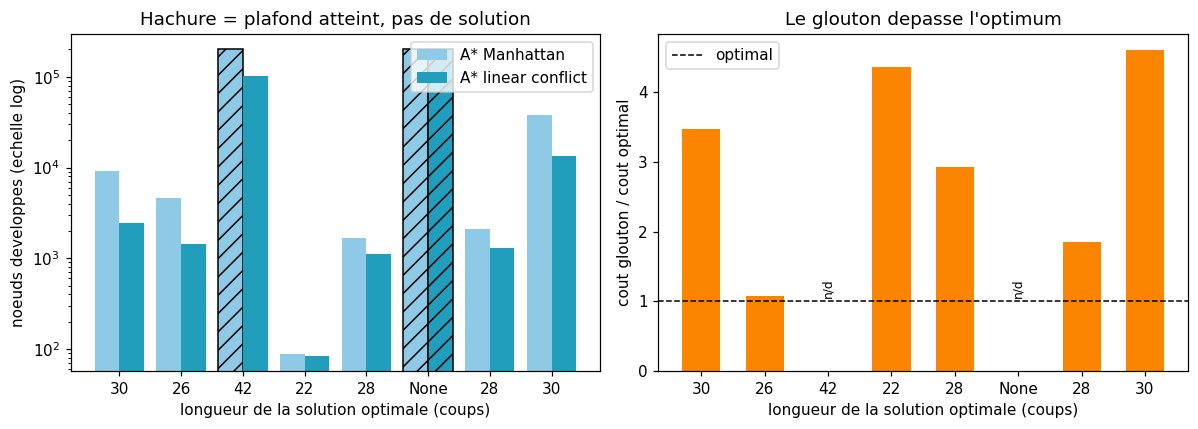

Barres hachurees (plafond) : 2 cote Manhattan, 1 cote linear conflict
Rapport de noeuds median (instances abouties des deux cotes) : 2.21x
Glouton : surcout median 3.20x, max 4.60x, non mesure sur 2 instance(s)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

positions = np.arange(len(rows))
noeuds_man = np.array([r[2] for r in rows], dtype=float)
noeuds_lc = np.array([r[5] for r in rows], dtype=float)
plafond_man = [not r[3] for r in rows]
plafond_lc = [not r[6] for r in rows]
longueurs = [r[1] if r[3] else r[4] for r in rows]

barres_man = axes[0].bar(positions - 0.2, noeuds_man, width=0.4,
                         label="A* Manhattan", color="#8ecae6")
barres_lc = axes[0].bar(positions + 0.2, noeuds_lc, width=0.4,
                        label="A* linear conflict", color="#219ebc")
for barre, plafond in list(zip(barres_man, plafond_man)) + list(zip(barres_lc, plafond_lc)):
    if plafond:
        barre.set_hatch("//")
        barre.set_edgecolor("black")
axes[0].set_yscale("log")
axes[0].set_xticks(positions)
axes[0].set_xticklabels([str(n) for n in longueurs])
axes[0].set_xlabel("longueur de la solution optimale (coups)")
axes[0].set_ylabel("noeuds developpes (echelle log)")
axes[0].set_title("Hachure = plafond atteint, pas de solution")
axes[0].legend()

ratio_cout = np.array([(r[7] / r[1]) if (r[9] and r[3]) else np.nan for r in rows], dtype=float)
axes[1].axhline(1.0, color="black", linewidth=1, linestyle="--", label="optimal")
for pos, valeur in zip(positions, ratio_cout):
    if np.isnan(valeur):
        axes[1].text(pos, 1.05, "n/d", ha="center", va="bottom", fontsize=8, rotation=90)
    else:
        axes[1].bar(pos, valeur, color="#fb8500", width=0.6)
axes[1].set_xticks(positions)
axes[1].set_xticklabels([str(n) for n in longueurs])
axes[1].set_xlabel("longueur de la solution optimale (coups)")
axes[1].set_ylabel("cout glouton / cout optimal")
axes[1].set_title("Le glouton depasse l'optimum")
axes[1].legend()

fig.tight_layout()
plt.show()

print(f"Barres hachurees (plafond) : {sum(plafond_man)} cote Manhattan, {sum(plafond_lc)} cote linear conflict")
print(f"Rapport de noeuds median (instances abouties des deux cotes) : {np.median(ratios_noeuds):.2f}x")
print(f"Glouton : surcout median {np.median(ratios_cout):.2f}x, max {ratios_cout.max():.2f}x, "
      f"non mesure sur {int(np.isnan(ratio_cout).sum())} instance(s)")

Le graphe de gauche est en échelle logarithmique pour une raison mesurable : les nœuds développés vont de quelques dizaines à plus de deux cent mille, et les barres hachurées ne sont pas des valeurs mais des **planchers** — la recherche a été arrêtée sans avoir trouvé de solution. Sur les puzzles les plus profonds, la même recherche est donc passée de « répond » à « ne répond pas » selon l'heuristique employée. Le graphe de droite montre l'autre face : quand la recherche gloutonne aboutit, elle paye sa vitesse en coups supplémentaires — et les deux instances où elle n'est pas comparable (`n/d`, faute d'optimum mesuré sous plafond) sont précisément les plus difficiles.

## Exercices

Les trois exercices suivants sont à compléter. Ils prolongent la mesure du carnet sur des variantes du problème.

### Exercice 1 — Le test de parité, écrit par vous

Réimplémentez `is_solvable` **sans regarder** la version de la section 2 : comptez les inversions, ajoutez la ligne de la case vide comptée depuis le bas, et rendez vrai si la somme est **impaire** — c'est la convention pour une largeur paire, et c'est le piège de cet exercice : la règle usuelle du 8-puzzle est la parité opposée. Validez votre version contre celle du carnet sur les 2 000 permutations uniformes déjà tirées : les deux doivent rendre **le même verdict** sur chacune.

*Indice :* `itertools.combinations(tiles, 2)` énumère les paires ; `state.index(0) // 4` donne la ligne de la case vide depuis le haut.

In [7]:
# Exercice 1 — a completer
# 1. Definissez est_resoluble(etat) : inversions + ligne de la case vide depuis le bas.
#    Attention : sur une largeur PAIRE la somme doit etre IMPAIRE (parite opposee au 8-puzzle).
# 2. Comparez votre verdict a is_solvable(etat) sur les 2000 permutations `shuffles`.
# 3. Affichez le nombre de desaccords (attendu : 0).

def est_resoluble(state):
    # TODO etudiant : compter les inversions, ajouter la ligne depuis le bas, tester la parite
    resultat = None  # TODO
    return resultat

# TODO : boucle de comparaison sur `shuffles`
print("Exercice a completer")

Exercice a completer


### Exercice 2 — Écrire `linear_conflict` soi-même, au-dessus de Manhattan

Le carnet utilise `linear_conflict` comme une boîte noire. Réimplémentez-la **à partir de `manhattan`** : deux tuiles qui doivent occuper la même ligne (ou la même colonne) que dans le but, et qui s'y trouvent dans l'ordre inverse, ne peuvent pas être remises en place en un seul passage — il faut au moins deux coups de plus que ce que Manhattan annonce. Ajoutez donc `2 × (nombre de conflits)` à `manhattan`, en vérifiant que la somme reste un **minorant** : sur les 500 états à distance exacte connue, aucune valeur ne doit dépasser `h*`. Confrontez ensuite votre version à celle du carnet sur l'échantillon (égalité attendue, valeur par valeur), puis mesurez sur les 8 instances du benchmark : **même coût de solution**, et même rapport de nœuds que celui du tableau ?

*Indice :* `state.index(tuile)` donne la position d'une tuile, dont on déduit ligne et colonne ; pour chaque ligne (puis chaque colonne), listez les tuiles en conflit, et comptez les paires dont l'objectif est inversé — une tuile ne participe qu'à un seul conflit par paire, et chaque paire coûte 2.

In [8]:
# Exercice 2 — a completer
# 1. Ecrire mon_linear_conflict(state) = manhattan(state) + 2 * nombre_de_conflits.
# 2. Verifier l'egalite avec linear_conflict(state) sur les 500 etats de `sample`.
# 3. Mesurer sur INSTANCES : cout identique ? rapport de noeuds comparable au tableau ?

def mon_linear_conflict(state):
    # TODO etudiant : compter les paires de tuiles en conflit sur chaque ligne et chaque colonne
    resultat = None  # TODO
    return resultat

print("Exercice a completer")

Exercice a completer


### Exercice 3 — A\* pondéré : acheter de la vitesse avec de l'optimalité

Lancez un A\* avec $f = g + w \cdot h$ pour $w \in \{1{,}0\,; 1{,}5\,; 2{,}0\,; 3{,}0\}$, sur les mêmes instances. Tracez le **compromis** : nœuds développés (axe des abscisses) contre surcoût de la solution par rapport à l'optimum (axe des ordonnées). À partir de quelle valeur de $w$ le surcoût devient-il visible, et le gain en nœuds vaut-il ce surcoût ?

*Indice :* $w > 1$ rend l'heuristique non admissible — c'est le principe même de la pondération. Le résultat attendu est une courbe en escalier : les solutions optimales survivent un moment, puis le surcoût apparaît.

In [9]:
# Exercice 3 — a completer
# 1. Parametrez astar avec un poids w sur h (f = g + w*h).
# 2. Pour chaque w, mesurez noeuds developpes et cout moyen sur INSTANCES.
# 3. Tracez le compromis noeuds vs surcout, et commentez le seuil.

def astar_pondere(start, heuristic, w, cap=NODE_CAP):
    # TODO etudiant : meme boucle que astar, cle de priorite g + w * h
    resultat = None  # TODO
    return resultat

print("Exercice a completer")

Exercice a completer


## Ce que le carnet a établi

| Affirmation | Statut dans ce carnet |
|---|---|
| Le 15-puzzle a deux classes d'états, résolubles et insolubles, de tailles voisines | **mesuré** (marches aléatoires toujours résolubles, permutations uniformes ≈ 50 %) |
| Manhattan et linear conflict sont admissibles | **mesuré** sur l'échantillon à distance exacte connue, zéro violation |
| Linear conflict domine Manhattan | **mesuré** (gain moyen positif sur 500 états éloignés du but, aucune exception) |
| A\* reste optimal avec les deux heuristiques | **mesuré** (coûts identiques partout où les deux aboutissent, et accord avec la distance exacte sur le contrôle) |
| Une heuristique plus forte développe moins de nœuds | **mesuré** (rapport des nœuds rapporté, et plafond atteint par Manhattan sur les instances profondes) |
| La recherche gloutonne est sous-optimale | **mesuré** (surcoût médian et maximal sur les instances où elle aboutit) |

Les limites à garder en tête : le parcours en largeur qui fournit la vérité terrain s'arrête à la distance 14 — au-delà, la frontière croît d'un facteur voisin de trois par niveau et la table ne tient plus en mémoire ; il sert donc de **contrôle d'optimalité**, pas de banc. Les instances du banc sont des marches aléatoires sans demi-tour de 34 à 46 coups, dont la profondeur réelle (le coût de la solution optimale) s'est révélée entre 28 et 40 — loin encore des positions de compétition (*15-puzzle optimal solver*, distance moyenne ≈ 53). Enfin, les deux heuristiques testées sont des minorants : pour ces positions-là il faudrait des heuristiques additives — somme de Manhattan et de conflits linéaires indépendants, ou bases de motifs (*pattern databases*).